# Forecasting California Gasoline Prices

This notebook answers the three questions in our project proposal:

1. **How accurately can we forecast California gasoline prices 4 and 12 weeks ahead?**
2. **Do crude oil prices lead California pump prices, and do pump prices rise faster than they fall?**
3. **Do AI forecasters beat conventional time-series models?**

### Key findings
*From the latest run (data through 2026-10-05; test period = 66 weekly forecasts from July 2025). Average error (MAE) in USD/gal, 4 / 12 weeks ahead.*

**1. How accurately can we forecast?** The most accurate model on the test period, **ARIMA + Fourier**, misses by 0.217 / 0.415 on average,
vs 0.270 / 0.600 for "same as this week" and 0.236 / 0.437 for the 10-year seasonal mean. It beats naive, but over a short test
period that includes a war the gain is not statistically significant (p = 0.15 / p = 0.24). The model picked in advance on the validation period, **ARIMAX**, scored 0.224 / 0.502: the validation winner did not stay on top in the test period, which is exactly the kind of result that choosing on the test period would have hidden.
Knowing future crude prices would cut ARIMAX's error by 20% / 44%: much of the remaining error is crude uncertainty.

**2. Does crude lead gasoline, and do prices rise faster than they fall?** Yes, crude leads (p < 0.001);
gasoline does not lead crude (p = 0.21). A 10% crude rise lifts California prices about 5.3% within 4 weeks.
Increases reach the pump faster in the first week (0.49 vs 0.24, p = 0.06, weak evidence),
but decreases catch up: the total effect is the same (p = 0.59).

**3. Do AI forecasters beat conventional models?** No. The best AI model, **TimesFM 2.5**, scores 0.256 / 0.582 vs 0.217 / 0.415 for ARIMA + Fourier (naive: 0.270 / 0.600). Combining an AI model with the best conventional model (ARIMAX + TimesFM 2.5: 0.228 / 0.515) does not help either.

*Section 9 recomputes these numbers each time the notebook runs.*

## How this notebook is organized

| Section | What it does |
|---|---|
| 0. Setup | Loads the weekly data built by `data_pull.py` |
| 1. Explore the data | Charts and tests that tell us how to build the models |
| 2. How we test the models | Splits time into training, validation and test periods |
| 3. Forecasting models | Benchmarks, ETS, ARIMA, ARIMAX and the AI models |
| 4. Which model is most accurate? | Picks models on the validation period, then scores everything once on the test period |
| 5. Does crude oil lead gasoline? | VAR, Granger causality and how a crude shock passes through |
| 6. Rockets and feathers | Do pump prices rise faster than they fall? |
| 7. AI vs conventional models | Research question 3 |
| 8. Scenario forecasts | What happens to gas prices if there is a war, a ceasefire or a refinery outage |
| 9. Summary | Recomputes the key findings shown at the top |

**Before running:** run `data_pull.py` (creates `data/weekly_data.csv`) and, for the AI models, `ai_models.py` and `ai_models.py --validation`. Every model's forecasts are saved in one shared format, `model, origin_date, horizon, target_date, forecast, lower80, upper80`, in `forecasts/` (test period) and `forecasts_validation/` (validation period).

## 0. Setup

Loads the libraries and the data, and sets the dates that split the data into periods. `df` holds one row per week (each Monday) with gasoline prices, crude prices, supply data and event flags.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("data/weekly_data.csv")
FC_DIR = Path("forecasts"); FC_DIR.mkdir(exist_ok=True)                 # test-period forecasts
VAL_DIR = Path("forecasts_validation"); VAL_DIR.mkdir(exist_ok=True)    # validation-period forecasts
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

TRAIN_END = "2025-06-30"   # last week before the test period
VAL_START = "2022-01-03"   # first validation forecast date
VAL_STEP = 4               # validation forecasts every 4th week
H = 12                     # forecast 1-12 weeks ahead
SCORE_H = [4, 12]          # the two horizons we score
Z80 = stats.norm.ppf(0.9)  # 80% interval = +/- 1.28 standard deviations
PERIOD = 365.25 / 7        # weeks in a year (~52.18)

df = pd.read_csv(DATA, index_col="date", parse_dates=True).asfreq("W-MON")
train = df.loc[:TRAIN_END]
print(f"{len(df)} weeks: {df.index.min().date()} -> {df.index.max().date()}")
df.tail(3)

1377 weeks: 2000-05-22 -> 2026-10-05


,ca_gas,us_gas,wti,brent,refinery_util_padd5,gas_stocks_padd5,refinery_util_us,gas_stocks_us,spread,log_ca_gas,...,log_brent,summer_blend,july_tax,covid,p66_la_closed,benicia_closed,chevron_es_fire,iraq_war,ukraine_war,iran_war_2026
date,,,,,,,,,,,,,,,,,,,,,
2026-09-21,6.003,4.478,103.542,124.146,94.9,27386,96.8,207732,1.525,1.792259,...,4.821458,1,0,0,1,1,0,0,0,1
2026-09-28,6.189,4.465,93.574,117.084,94.5,27328,94.0,206046,1.724,1.822774,...,4.762892,1,0,0,1,1,0,0,0,1
2026-10-05,6.227,4.354,98.074,120.034,93.4,27990,92.5,204362,1.873,1.828895,...,4.787775,1,0,0,1,1,0,0,0,1


## 1. Explore the data

### 1.1 Prices over time
**What:** California vs U.S. gasoline, the gap between them (the "California premium"), and California gasoline against Brent crude. Grey bands mark wars and COVID.

**How to read it:** California is always more expensive, and the premium has widened from about \$0.30 to over \$1.50 since 2015. Gasoline and crude move together, so crude is a natural predictor.

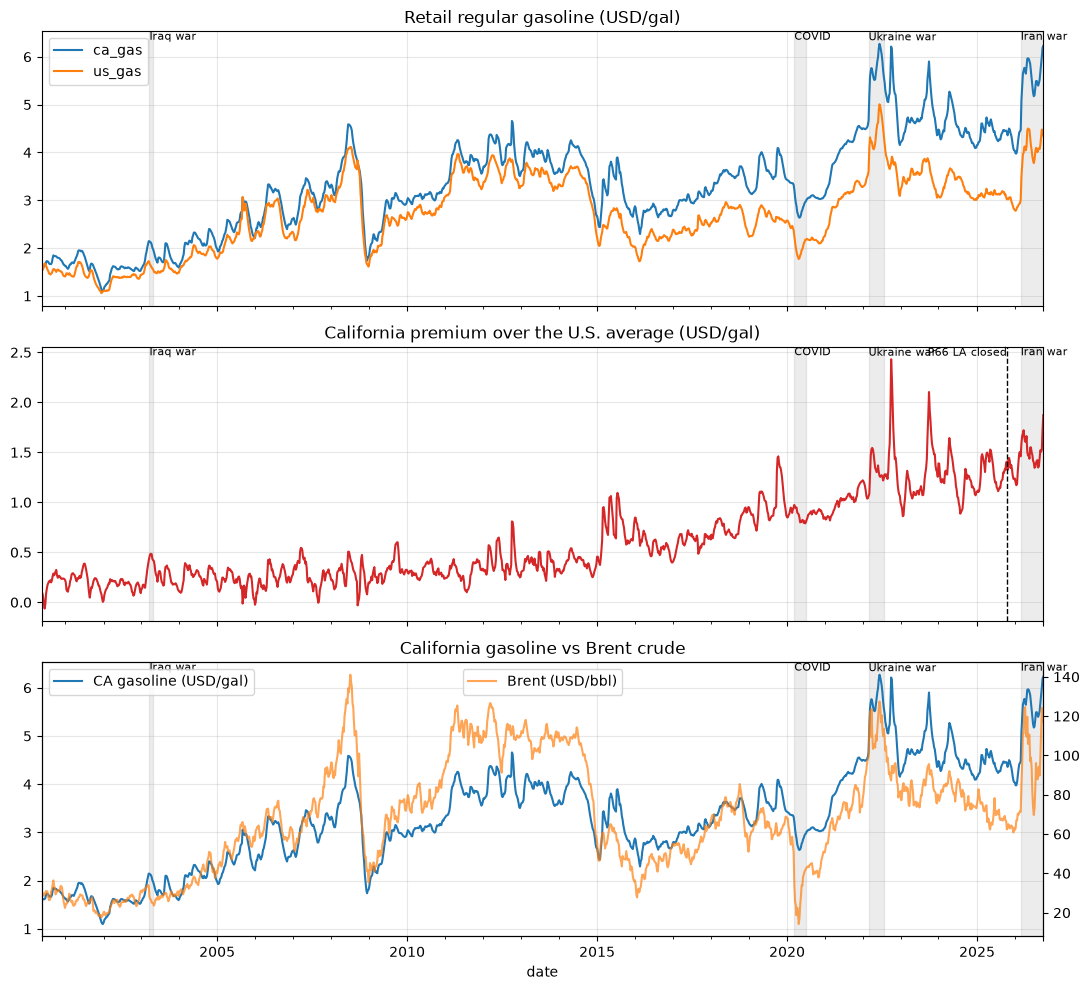

In [2]:
EVENTS = {  # shaded on the charts
    "Iraq war": ("2003-03-24", "2003-04-28"), "COVID": ("2020-03-16", "2020-06-30"),
    "Ukraine war": ("2022-02-28", "2022-07-25"), "Iran war": ("2026-03-02", df.index.max()),
}

def shade(ax):
    for name, (a, b) in EVENTS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15)
        ax.text(pd.Timestamp(a), ax.get_ylim()[1], name, fontsize=8, va="top")

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
df[["ca_gas", "us_gas"]].plot(ax=axes[0], title="Retail regular gasoline (USD/gal)")
df["spread"].plot(ax=axes[1], color="C3", title="California premium over the U.S. average (USD/gal)")
axes[1].axvline(pd.Timestamp("2025-10-20"), color="k", ls="--", lw=1)
axes[1].text(pd.Timestamp("2025-10-20"), axes[1].get_ylim()[1], " P66 LA closed", fontsize=8, va="top", ha="right")
ax2 = axes[2]; df["ca_gas"].plot(ax=ax2, color="C0", label="CA gasoline (USD/gal)")
ax2b = ax2.twinx(); df["brent"].plot(ax=ax2b, color="C1", alpha=0.7, label="Brent (USD/bbl)")
ax2.set_title("California gasoline vs Brent crude"); ax2b.grid(False)
ax2.legend(loc="upper left"); ax2b.legend(loc="upper center")
for ax in axes: shade(ax)
plt.tight_layout(); plt.show()

### 1.2 Seasonal pattern
**What:** splits the price (training data only) into a long-run trend, a repeating yearly pattern, and noise (STL decomposition).

**Why:** if prices follow a yearly pattern, our models need to include it.

**How to read it:** the bar chart shows how far each month is above or below normal. Spring and summer are more expensive because California requires a costlier summer fuel blend.

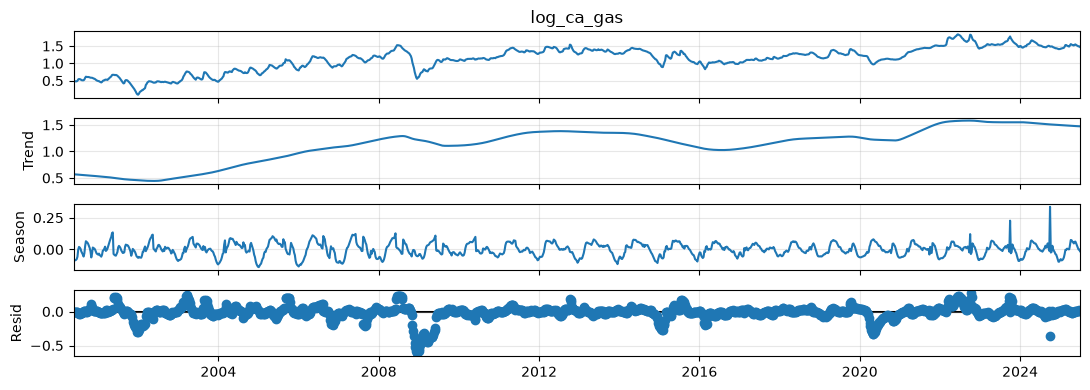

Summer (Apr-Oct) prices are about 6.2% higher than winter prices


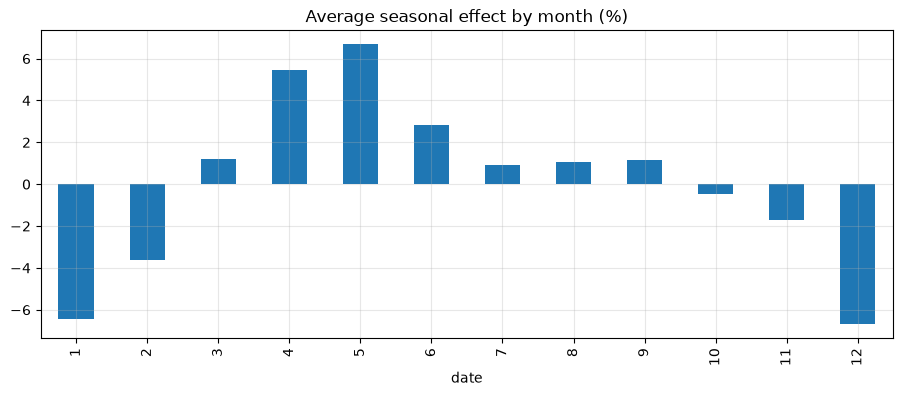

In [3]:
stl = STL(train["log_ca_gas"], period=52, robust=True).fit()
stl.plot(); plt.show()

seas = stl.seasonal.groupby(stl.seasonal.index.month).mean()
premium = np.exp(seas.loc[4:10].mean() - seas.drop(range(4, 11)).mean()) - 1
print(f"Summer (Apr-Oct) prices are about {premium:.1%} higher than winter prices")
(np.exp(seas) - 1).mul(100).plot(kind="bar", title="Average seasonal effect by month (%)"); plt.show()

### 1.3 Do prices wander, or return to an average? (unit-root tests)
**What:** two standard tests of whether a series is *stationary* (keeps returning to a stable average).
- **ADF test:** a p-value **below 0.05** means stationary.
- **KPSS test:** a p-value **below 0.05** means *not* stationary.

**Why:** ARIMA models need a stationary series. If prices wander but weekly *changes* are stationary, we model changes (d = 1 in ARIMA).

**How to read it:** prices (log) wander; weekly changes are stationary. So we use d = 1.

In [4]:
def unit_root_table(series_dict):
    rows = []
    for name, s in series_dict.items():
        s = s.dropna()
        rows.append({"series": name, "ADF p": adfuller(s, autolag="AIC")[1],
                     "KPSS p": kpss(s, regression="c", nlags="auto")[1]})
    return pd.DataFrame(rows).set_index("series").round(3)

unit_root_table({
    "log CA gas price": train["log_ca_gas"], "weekly change in log CA gas": train["log_ca_gas"].diff(),
    "log Brent": train["log_brent"], "weekly change in log Brent": train["log_brent"].diff(),
    "CA premium (spread)": train["spread"],
})

,ADF p,KPSS p
series,,
log CA gas price,0.142,0.01
weekly change in log CA gas,0.000,0.10
log Brent,0.117,0.01
weekly change in log Brent,0.000,0.10
CA premium (spread),0.734,0.01


### 1.4 How much does this week's change depend on past weeks? (ACF / PACF)
**What:** the correlation between this week's price change and the change 1, 2, 3... weeks earlier.

**Why:** it guides how many past weeks the ARIMA model should use.

**How to read it:** bars outside the blue band are real patterns. The first few lags are large: when prices start rising, they tend to keep rising for a few weeks.

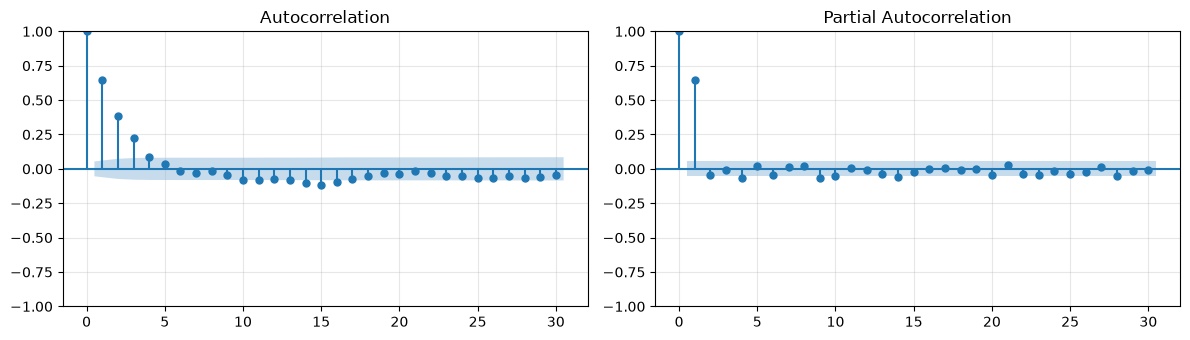

In [5]:
dy = train["log_ca_gas"].diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(dy, lags=30, ax=axes[0]); plot_pacf(dy, lags=30, ax=axes[1], method="ywm")
plt.tight_layout(); plt.show()

### 1.5 How many weeks does crude oil lead gasoline?
**What:** the correlation between this week's gasoline change and the crude change *k* weeks earlier.

**How to read it:** bars above the red dashed line are significant. Crude changes show up in pump prices within about 0–5 weeks, strongest in the first two.

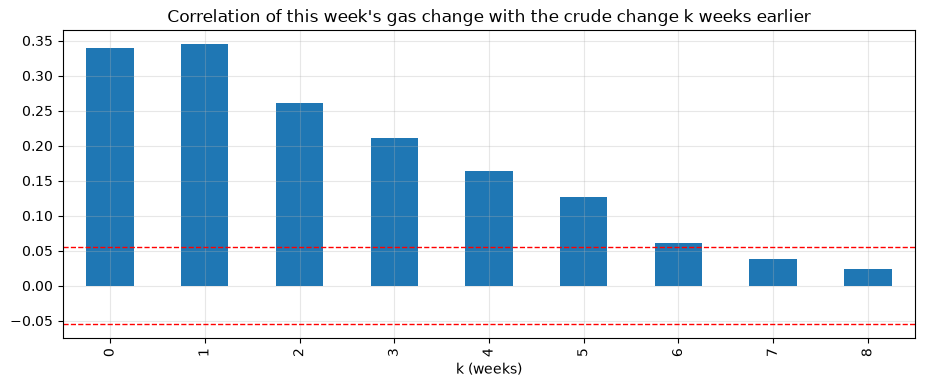

0    0.339
1    0.345
2    0.261
3    0.211
4    0.163
5    0.127
6    0.061
7    0.038
8    0.023


In [6]:
dc = train["log_brent"].diff().dropna()
dy, dc = dy.align(dc, join="inner")
xc = pd.Series([dy.corr(dc.shift(k)) for k in range(9)], index=range(9))
ax = xc.plot(kind="bar", title="Correlation of this week's gas change with the crude change k weeks earlier")
ax.axhline(2 / np.sqrt(len(dy)), color="r", ls="--", lw=1); ax.axhline(-2 / np.sqrt(len(dy)), color="r", ls="--", lw=1)
ax.set_xlabel("k (weeks)"); plt.show()
print(xc.round(3).to_string())

## 2. How we test the models

We pretend to be a forecaster in the past: at each **forecast date** we fit the model using only data available that week, forecast the next 1–12 weeks, then compare with what actually happened.

| Period | Dates | Used for |
|---|---|---|
| **Training** | May 2000 – June 2025 | Estimating models and choosing their basic settings (e.g. ARIMA order) |
| **Validation** | Forecast dates Jan 2022 – Apr 2025, every 4th week | **Choosing between models** (which ARIMAX version, which models to combine). All its targets end by June 2025 |
| **Test** | Forecast dates July 2025 – Sept 2026, every week | **Final scoring only.** No choice is ever made by looking at test results |

Keeping the test period untouched matters: if we picked the model that happened to score best on the test period, its score would look better than it really is.

**No peeking at the future:** models that use crude oil assume crude stays at its last known price; event flags keep their value from the forecast date.

In [7]:
ORIGINS = df.loc[TRAIN_END:].index[:-1]   # test forecast dates (the last week has nothing left to score)
idx = df.index
VAL_ORIGINS = idx[(idx >= VAL_START) & (idx <= pd.Timestamp(TRAIN_END) - pd.Timedelta(weeks=H))][::VAL_STEP]
print(f"Test:       {len(ORIGINS)} forecast dates, {ORIGINS[0].date()} -> {ORIGINS[-1].date()}")
print(f"Validation: {len(VAL_ORIGINS)} forecast dates, {VAL_ORIGINS[0].date()} -> {VAL_ORIGINS[-1].date()}")


def backtest(name, fit_forecast, origins=ORIGINS, out_dir=FC_DIR, h=H, verbose=True):
    # At every forecast date: fit on data up to that date, forecast h weeks, save in the shared format.
    out = []
    for i, origin in enumerate(origins):
        fc = fit_forecast(df.loc[:origin], h).copy()
        fc["horizon"] = range(1, h + 1)
        fc["origin_date"] = origin
        fc["target_date"] = origin + pd.to_timedelta(7 * fc["horizon"], unit="D")
        out.append(fc)
        if verbose and (i % 20 == 0 or i == len(origins) - 1):
            print(f"  {name}: {i + 1}/{len(origins)} forecast dates")
    out = pd.concat(out, ignore_index=True)
    out.insert(0, "model", name)
    out = out[["model", "origin_date", "horizon", "target_date", "forecast", "lower80", "upper80"]]
    out.to_csv(out_dir / f"{name}.csv", index=False)
    return out


def run_both(name, fit_forecast):
    # Run a model on the validation period and on the test period.
    val[name] = backtest(name, fit_forecast, VAL_ORIGINS, VAL_DIR, verbose=False)
    forecasts[name] = backtest(name, fit_forecast)


def from_log(mean, sd=None, lower=None, upper=None):
    # Models work with log prices; convert back to USD/gal.
    if sd is not None:
        lower, upper = mean - Z80 * sd, mean + Z80 * sd
    return pd.DataFrame({"forecast": np.exp(np.asarray(mean)), "lower80": np.exp(np.asarray(lower)),
                         "upper80": np.exp(np.asarray(upper))}, index=range(1, len(mean) + 1))

forecasts, val = {}, {}   # test-period and validation-period forecasts, by model

Test:       66 forecast dates, 2025-06-30 -> 2026-09-28
Validation: 43 forecast dates, 2022-01-03 -> 2025-03-24


## 3. Forecasting models

### 3.1 Benchmarks: simple rules every model must beat
- **Naive:** next weeks' price = this week's price.
- **Seasonal naive:** price = the price 52 weeks earlier.
- **Seasonal mean (10 years):** this week's price, moved by the average change over the same weeks of the year in the previous 10 years. Simple, but hard to beat because California prices have a strong yearly pattern.

**About the 80% intervals:** each forecast comes with a range that should contain the actual price 80% of the time. For the naive forecast we use the actual spread of past h-week price changes. The textbook shortcut (weekly spread × √h) assumes each week's change is unrelated to the last, which is false for gas prices, so it gives ranges that are much too narrow.

In [8]:
def naive_ff(train, h):
    y = train["log_ca_gas"]
    sd = np.array([y.diff(k).std() for k in range(1, h + 1)])   # spread of actual k-week changes
    return from_log(np.repeat(y.iloc[-1], h), sd=sd)

def snaive_ff(train, h):
    y = train["log_ca_gas"]
    return from_log(y.iloc[-52:-52 + h].values, sd=np.repeat(y.diff(52).std(), h))

def seasonal_change(y, t, k, years=10, min_years=5):
    # Average log change over weeks t..t+k at this time of year in each of the previous `years` years.
    terms = [y[b + k] - y[b] for yr in range(1, years + 1) if (b := t - int(round(yr * PERIOD))) >= 0]
    return np.mean(terms) if len(terms) >= min_years else np.nan

def smean_ff(train, h):
    y = train["log_ca_gas"].values
    T = len(y) - 1
    fc = np.array([seasonal_change(y, T, k) for k in range(1, h + 1)])
    sd = np.array([np.nanstd([y[t + k] - y[t] - seasonal_change(y, t, k) for t in range(T - 520, T - k + 1)])
                   for k in range(1, h + 1)])   # spread of this rule's own past errors
    return from_log(y[-1] + fc, sd=sd)

for name, ff in [("naive", naive_ff), ("snaive", snaive_ff), ("smean", smean_ff)]:
    run_both(name, ff)

  naive: 1/66 forecast dates
  naive: 21/66 forecast dates


  naive: 41/66 forecast dates


  naive: 61/66 forecast dates


  naive: 66/66 forecast dates


  snaive: 1/66 forecast dates
  snaive: 21/66 forecast dates
  snaive: 41/66 forecast dates
  snaive: 61/66 forecast dates
  snaive: 66/66 forecast dates


  smean: 1/66 forecast dates


  smean: 21/66 forecast dates


  smean: 41/66 forecast dates


  smean: 61/66 forecast dates


  smean: 66/66 forecast dates


### 3.2 ETS (exponential smoothing)
**What:** a forecast built from a weighted average of past prices, where recent weeks count more. It can include a trend that continues or slowly flattens out ("damped").

**How the settings are chosen:** we try no trend, a trend, and a damped trend on the training data and keep the one with the lowest AICc (a score that rewards fit but penalizes complexity).

In [9]:
y_train = train["log_ca_gas"]
ets_specs = {"no trend": dict(trend=None), "trend": dict(trend="add"), "damped trend": dict(trend="add", damped_trend=True)}
ets_aicc = {k: ETSModel(y_train, error="add", **v).fit(disp=False).aicc for k, v in ets_specs.items()}
ETS_SPEC = ets_specs[min(ets_aicc, key=ets_aicc.get)]
print(pd.Series(ets_aicc).round(1).to_string(), "\nChosen:", min(ets_aicc, key=ets_aicc.get))

def ets_ff(train, h):
    y = train["log_ca_gas"]
    res = ETSModel(y, error="add", **ETS_SPEC).fit(disp=False)
    pr = res.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)
    return from_log(pr["mean"], lower=pr["pi_lower"], upper=pr["pi_upper"])

run_both("ets", ets_ff)

no trend       -6187.6
trend          -6664.9
damped trend   -6841.5 
Chosen: damped trend


  ets: 1/66 forecast dates


  ets: 21/66 forecast dates


  ets: 41/66 forecast dates


  ets: 61/66 forecast dates


  ets: 66/66 forecast dates


### 3.3 ARIMA with a yearly pattern (ARIMA + Fourier)
**What:** ARIMA predicts next week's price change from recent price changes and recent forecast errors. We add smooth sine/cosine waves with a one-year cycle (Fourier terms) to capture the seasonal pattern from 1.2.

**How the settings are chosen:** on the training data, AIC picks the number of waves (K) and the ARIMA order (p, q). The settings stay fixed; only the coefficients are re-estimated at each forecast date.

In [10]:
T0 = df.index[0]

def fourier(dates, K):
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD)
                         for k in range(1, K + 1) for f, fn in (("sin", np.sin), ("cos", np.cos))}, index=dates)

def fit_sarimax(y, X, order, start_params=None):
    return SARIMAX(y, exog=X, order=order, trend="n").fit(disp=False, start_params=start_params, maxiter=200)

aic_K = {K: fit_sarimax(y_train, fourier(y_train.index, K), (1, 1, 1)).aic for K in range(1, 5)}
K_BEST = min(aic_K, key=aic_K.get)
aic_pq = {(p, q): fit_sarimax(y_train, fourier(y_train.index, K_BEST), (p, 1, q)).aic
          for p in range(4) for q in range(4)}
p_best, q_best = min(aic_pq, key=aic_pq.get)
ORDER = (p_best, 1, q_best)
print(f"Number of yearly waves K = {K_BEST}, ARIMA order = {ORDER}")

def future_dates(train, h):
    return pd.date_range(train.index[-1] + pd.Timedelta(days=7), periods=h, freq="W-MON")

def make_arima_ff():
    state = {}
    def ff(train, h):
        y = train["log_ca_gas"]
        res = fit_sarimax(y, fourier(y.index, K_BEST), ORDER, state.get("params"))
        state["params"] = res.params
        pr = res.get_forecast(h, exog=fourier(future_dates(train, h), K_BEST)).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

run_both("arima_fourier", make_arima_ff())

Number of yearly waves K = 3, ARIMA order = (3, 1, 2)


  arima_fourier: 1/66 forecast dates


  arima_fourier: 21/66 forecast dates


  arima_fourier: 41/66 forecast dates


  arima_fourier: 61/66 forecast dates


  arima_fourier: 66/66 forecast dates


### 3.4 ARIMAX: ARIMA plus crude oil and events
**What:** the ARIMA model above, plus Brent crude prices, the summer-blend and July-tax calendar, and event flags (COVID, wars, refinery closures and fires).

**Two ways to add crude, and how we choose:**
- **Crude as price levels** — a crude move permanently shifts the gasoline forecast.
- **Crude as weekly changes** — a crude move affects gasoline for a few weeks, then fades.

For each version, BIC on the training data picks how many past weeks of crude to use. Then the **validation period** picks the version with the lower average error. The other version is saved for reference but never ranked.

**No peeking:** each week's crude value is the average of the 7 days *before* that Monday, so it is already known when the Monday gas price is reported. Future crude is assumed to stay at its last known price.

In [11]:
EVENT_DUMMIES = ["covid", "iraq_war", "ukraine_war", "chevron_es_fire", "p66_la_closed", "benicia_closed", "iran_war_2026"]
LAG_SETS = {"0-1": range(0, 2), "0-3": range(0, 4), "0-4": range(0, 5), "0-8": range(0, 9), "1-4": range(1, 5)}

def calendar_dummies(dates):
    return pd.DataFrame({"summer_blend": dates.month.isin(range(4, 11)).astype(int),
                         "july_tax": ((dates.month == 7) & (dates.day <= 28)).astype(int)}, index=dates)

def arimax_exog(train, h, form, lags, future_brent=None):
    # Inputs for the training weeks and the h future weeks, using only what is known at the forecast date.
    # future_brent=None: crude stays at its last value. A Series = the actual future path (oracle check only).
    fut = future_dates(train, h)
    last = train["log_brent"].iloc[-1]
    lb_fut = pd.Series(last, index=fut) if future_brent is None else future_brent.reindex(fut).fillna(future_brent.iloc[-1])
    lb = pd.concat([train["log_brent"], lb_fut])
    base = lb if form == "levels" else lb.diff()
    crude = pd.DataFrame({f"brent_{form}_l{k}": base.shift(k) for k in lags})
    events = [c for c in EVENT_DUMMIES if train[c].nunique() > 1]   # skip events that haven't happened yet
    ev = pd.concat([train[events], pd.DataFrame([train[events].iloc[-1].values] * h, index=fut, columns=events)])
    X = pd.concat([fourier(crude.index, K_BEST), crude, calendar_dummies(crude.index), ev], axis=1).iloc[max(lags) + 1:]
    return X.loc[:train.index[-1]], X.loc[fut]

def make_arimax_ff(form, lags, future_brent=None):
    state = {}
    def ff(train, h):
        X, Xf = arimax_exog(train, h, form, lags, future_brent)
        key = tuple(X.columns)   # events switch on over time; reuse start values only for the same inputs
        res = fit_sarimax(train["log_ca_gas"].loc[X.index], X, ORDER, state.get(key))
        state[key] = res.params
        pr = res.get_forecast(h, exog=Xf).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

# Step 1: for each crude version, BIC on the training data picks the number of crude lags
bic_rows, ARIMAX_LAGS = [], {}
for form in ["levels", "changes"]:
    for name, lags in LAG_SETS.items():
        X_tr, _ = arimax_exog(train, 1, form, lags)
        X_tr = X_tr.loc[train.index[10]:]   # same estimation weeks for every option
        r = fit_sarimax(train["log_ca_gas"].loc[X_tr.index], X_tr, ORDER)
        bic_rows.append({"crude version": form, "lags": name, "BIC": round(r.bic, 1)})
    best = min((r for r in bic_rows if r["crude version"] == form), key=lambda r: r["BIC"])
    ARIMAX_LAGS[form] = LAG_SETS[best["lags"]]
    print(f"Crude as {form}: BIC picks lags {best['lags']}")

# Step 2: the validation period picks the version
val_err = {}
for form in ["levels", "changes"]:
    f = backtest(f"arimax_{form}", make_arimax_ff(form, ARIMAX_LAGS[form]), VAL_ORIGINS, VAL_DIR, verbose=False)
    f["actual"] = f["target_date"].map(df["ca_gas"])
    val_err[form] = {h: (f[f.horizon == h].actual - f[f.horizon == h].forecast).abs().mean() for h in SCORE_H}
val_err = pd.DataFrame(val_err).T
val_err["average"] = val_err.mean(axis=1)
ARIMAX_FORM = val_err["average"].idxmin()
OTHER_FORM = "changes" if ARIMAX_FORM == "levels" else "levels"
print("\nValidation error (MAE, USD/gal):\n", val_err.round(3).to_string(), f"\n-> ARIMAX uses crude as {ARIMAX_FORM}")

# Step 3: run the chosen version on the test period; save the other version for reference only
val["arimax"] = pd.read_csv(VAL_DIR / f"arimax_{ARIMAX_FORM}.csv", parse_dates=["origin_date", "target_date"]).assign(model="arimax")
forecasts["arimax"] = backtest("arimax", make_arimax_ff(ARIMAX_FORM, ARIMAX_LAGS[ARIMAX_FORM]))
other = backtest(f"arimax_{OTHER_FORM}", make_arimax_ff(OTHER_FORM, ARIMAX_LAGS[OTHER_FORM]), verbose=False)
(FC_DIR / f"arimax_{OTHER_FORM}.csv").replace(RES_DIR / f"arimax_{OTHER_FORM}_test_reference.csv")

Crude as levels: BIC picks lags 0-8


Crude as changes: BIC picks lags 0-8



Validation error (MAE, USD/gal):
              4     12  average
levels   0.203  0.339    0.271
changes  0.205  0.361    0.283 
-> ARIMAX uses crude as levels


  arimax: 1/66 forecast dates


  arimax: 21/66 forecast dates


  arimax: 41/66 forecast dates


  arimax: 61/66 forecast dates


  arimax: 66/66 forecast dates


PosixPath('results/arimax_changes_test_reference.csv')

### 3.5 AI models
**What:** three pretrained AI forecasters — **Chronos-Bolt** and **Chronos-2** (Amazon) and **TimesFM 2.5** (Google). They were never trained on our data ("zero-shot"); each one just reads the last 512 weeks of California prices and forecasts the next 12.

They need PyTorch, so `ai_models.py` runs them separately and saves forecasts in the same format; this cell loads them. LLM forecasts (Claude, ChatGPT) from `llm/llm_experiments.py` are loaded too if they exist.

In [12]:
AI_PREFIXES = ("chronos", "timesfm", "llm_")
is_ai = lambda m: m.startswith(AI_PREFIXES)
for folder, store in [(FC_DIR, forecasts), (VAL_DIR, val)]:
    for f in sorted(folder.glob("*.csv")):
        if is_ai(f.stem):
            store[f.stem] = pd.read_csv(f, parse_dates=["origin_date", "target_date"])
print("AI models, test period:      ", [m for m in forecasts if is_ai(m)] or "none (run ai_models.py)")
print("AI models, validation period:", [m for m in val if is_ai(m)] or "none (run ai_models.py --validation)")
ai_log = RES_DIR / "ai_model_log.csv"
pd.read_csv(ai_log)[["model", "repo", "released", "release_inside_test_period"]] if ai_log.exists() else None

AI models, test period:       ['chronos2', 'chronos_bolt', 'timesfm']
AI models, validation period: ['chronos2', 'chronos_bolt', 'timesfm']


,model,repo,released,release_inside_test_period
0,chronos_bolt,amazon/chronos-bolt-small,2024-11-25,False
1,chronos2,amazon/chronos-2,2025-10-30,True
2,timesfm,google/timesfm-2.5-200m-pytorch,2025-09-02,True


## 4. Which model is most accurate?

**How accuracy is measured** (each at 4 and 12 weeks ahead):
- **MAE:** average size of the miss, in dollars per gallon. *Lower is better.*
- **RMSE / MAPE:** like MAE, but RMSE punishes big misses more and MAPE is in percent.
- **Skill vs naive:** the model's MAE divided by the naive MAE. *Below 1 means it beats "same as this week".*
- **Coverage80:** how often the actual price fell inside the 80% range. *Should be close to 0.80.*
- **DirAcc:** how often the model called the direction (up or down) correctly. *A coin flip scores 50%.* Naive always predicts "no change", so it has no score.

### 4.1 Choices made on the validation period
**What:** scores every model on the validation period, then makes two choices:
1. the **best conventional model** — the benchmark used in the significance tests;
2. the **forecast combination** — the average of the best conventional and the best AI model, which tests whether AI adds anything the conventional models miss.

The score used is the average MAE at 4 and 12 weeks. The test period is not looked at here.

In [13]:
def evaluate(fc_dict):
    # Attach actual prices to every forecast and compute the accuracy measures.
    all_fc = pd.concat(fc_dict.values(), ignore_index=True)
    all_fc["actual"] = all_fc["target_date"].map(df["ca_gas"])
    all_fc = all_fc.dropna(subset=["actual"])
    all_fc["err"] = all_fc["actual"] - all_fc["forecast"]
    all_fc["covered"] = all_fc["actual"].between(all_fc["lower80"], all_fc["upper80"])
    origin_price = all_fc["origin_date"].map(df["ca_gas"])
    f_move, a_move = all_fc["forecast"] - origin_price, all_fc["actual"] - origin_price
    f_dir = np.where(f_move.abs() < 1e-6, 0, np.sign(f_move))    # "no change" forecasts don't count
    all_fc["dir_ok"] = np.where(f_dir == 0, np.nan, (f_dir == np.sign(a_move)).astype(float))
    sc = all_fc[all_fc["horizon"].isin(SCORE_H)].assign(
        abs_err=lambda d: d.err.abs(), sq_err=lambda d: d.err ** 2, ape=lambda d: (d.err / d.actual).abs() * 100)
    m = sc.groupby(["horizon", "model"]).agg(
        n=("err", "size"), MAE=("abs_err", "mean"), RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
        MAPE=("ape", "mean"), Coverage80=("covered", "mean"), DirAcc=("dir_ok", lambda s: s.mean() * 100))
    naive_mae = m["MAE"].xs("naive", level="model")
    m["Skill_vs_naive"] = m["MAE"] / naive_mae.reindex(m.index.get_level_values("horizon")).values
    return all_fc, m.round(3)

_, val_metrics = evaluate(val)
val_score = val_metrics["MAE"].unstack("horizon").mean(axis=1).rename("average MAE")
val_table = val_metrics["MAE"].unstack("horizon").add_prefix("MAE h=").join(val_score).sort_values("average MAE").round(3)

CONVENTIONAL = ["ets", "arima_fourier", "arimax"]
best_conv = val_score[CONVENTIONAL].idxmin()
ai_val = [m for m in val_score.index if is_ai(m) and not m.startswith("llm_")]
best_ai = val_score[ai_val].idxmin() if ai_val else None
COMBO = [best_conv, best_ai] if best_ai else list(val_score[CONVENTIONAL].nsmallest(2).index)
print(f"Best conventional model on validation: {best_conv}")
print(f"Best AI model on validation:           {best_ai}")
print(f"Combination = average of {COMBO}")
val_table.to_csv(RES_DIR / "validation_metrics.csv")
val_table

Best conventional model on validation: arimax
Best AI model on validation:           timesfm
Combination = average of ['arimax', 'timesfm']


,MAE h=4,MAE h=12,average MAE
model,,,
arimax,0.203,0.339,0.271
arima_fourier,0.199,0.366,0.282
smean,0.256,0.371,0.314
timesfm,0.213,0.473,0.343
ets,0.219,0.499,0.359
chronos2,0.245,0.490,0.368
naive,0.285,0.480,0.382
chronos_bolt,0.278,0.490,0.384
snaive,0.715,0.672,0.694


### 4.2 Test-period results
**What:** every model scored once on the untouched test period (July 2025 onward), including the combination chosen above.

**How to read it:** sorted by MAE within each horizon. Compare each model with *naive* (does it beat the simplest rule?) and with the *seasonal mean* (a tougher benchmark). LLM rows, if present, cover only their 17 forecast dates — see section 7 for a fair comparison.

In [14]:
combo = (pd.concat([forecasts[m] for m in COMBO])
         .groupby(["origin_date", "horizon", "target_date"], as_index=False)[["forecast", "lower80", "upper80"]].mean())
combo.insert(0, "model", "combo")
combo.to_csv(FC_DIR / "combo.csv", index=False)
forecasts["combo"] = combo

all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.sort_values(["horizon", "MAE"])

n    MAE   RMSE    MAPE  Coverage80  DirAcc  \
horizon model                                                         
4       arima_fourier  63  0.217  0.310   4.103       0.810  71.429   
        arimax         63  0.224  0.332   4.214       0.714  74.603   
        combo          63  0.228  0.336   4.330       0.810  71.429   
        smean          63  0.236  0.311   4.601       0.794  63.492   
        timesfm        63  0.256  0.361   4.909       0.746  63.492   
        naive          63  0.270  0.384   5.233       0.794     NaN   
        chronos2       63  0.273  0.384   5.205       0.730  58.730   
        chronos_bolt   63  0.277  0.384   5.308       0.683  55.556   
        ets            63  0.281  0.378   5.374       0.841  63.492   
        snaive         63  0.631  0.848  11.421       0.841  57.143   
12      arima_fourier  55  0.415  0.574   7.643       0.745  76.364   
        smean          55  0.437  0.619   7.883       0.764  81.818   
        arimax         55  0.502  0.680   9.166       0.618  70.909   
        combo          55  0.515  0.734   9.338       0.709  67.273   
        chronos2       55  0.575  0.818  10.566       0.673  56.364   
        chronos_bolt   55  0.579  0.829  10.592       0.691  56.364   
        timesfm        55  0.582  0.820  10.697       0.709  54.545   
        naive          55  0.600  0.812  11.109       0.782     NaN   
        snaive         55  0.715  0.907  12.895       0.818  81.818   
        ets            55  0.725  0.904  13.502       0.836  41.818   

                       Skill_vs_naive  
horizon model                          
4       arima_fourier           0.803  
        arimax                  0.827  
        combo                   0.845  
        smean                   0.871  
        timesfm                 0.948  
        naive                   1.000  
        chronos2                1.009  
        chronos_bolt            1.025  
        ets                     1.039  
        snaive                  2.335  
12      arima_fourier           0.691  
        smean                   0.728  
        arimax                  0.837  
        combo                   0.859  
        chronos2                0.959  
        chronos_bolt            0.966  
        timesfm                 0.970  
        naive                   1.000  
        snaive                  1.192  
        ets                     1.208

### 4.3 Are the differences real or luck? (Diebold-Mariano test)
**What:** tests whether two models' errors differ by more than chance. Each model is compared with naive and with the best conventional model from 4.1.

**How to read it:** a **negative DM** means the model is more accurate than the one it is compared with; **p below 0.05** means the difference is unlikely to be luck. With only about 60 test weeks, which include a war, even sizable differences are often not significant.

In [15]:
def dm_test(e1, e2, h, power=2):
    # Diebold-Mariano test with HAC variance (h-1 lags) and the Harvey-Leybourne-Newbold correction
    d = np.abs(e1) ** power - np.abs(e2) ** power
    n, dbar = len(d), d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:
        var = gamma[0] / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

rows = []
for h in SCORE_H:
    e = all_fc[all_fc.horizon == h].pivot(index="origin_date", columns="model", values="err")
    for m in e.columns:
        for bench in ["naive", best_conv]:
            if m != bench:
                pair = e[[m, bench]].dropna()   # compare only on dates both models forecast
                dm, p = dm_test(pair[m].values, pair[bench].values, h)
                rows.append({"horizon": h, "model": m, "vs": bench, "n": len(pair), "DM": dm, "p": p})
dm_table = pd.DataFrame(rows).round(3)
dm_table.to_csv(RES_DIR / "dm_tests.csv", index=False)
dm_table[dm_table.vs == "naive"].sort_values(["horizon", "DM"])

,horizon,model,vs,n,DM,p
0,4,arima_fourier,naive,63,-1.466,0.148
12,4,smean,naive,63,-1.450,0.152
7,4,combo,naive,63,-1.176,0.244
16,4,timesfm,naive,63,-0.997,0.323
2,4,arimax,naive,63,-0.918,0.362
9,4,ets,naive,63,-0.180,0.858
5,4,chronos_bolt,naive,63,-0.025,0.980
3,4,chronos2,naive,63,-0.014,0.989
14,4,snaive,naive,63,2.254,0.028
30,12,smean,naive,55,-1.463,0.149


### 4.4 Forecasts vs what actually happened
**What:** each line is the forecast made 4 (top) or 12 (bottom) weeks earlier for that date; black is the actual price. The shaded band is the best conventional model's 80% range.

**How to read it:** the gap between a colored line and the black line is the error. All models lag behind sudden jumps such as the start of the 2026 Iran war.

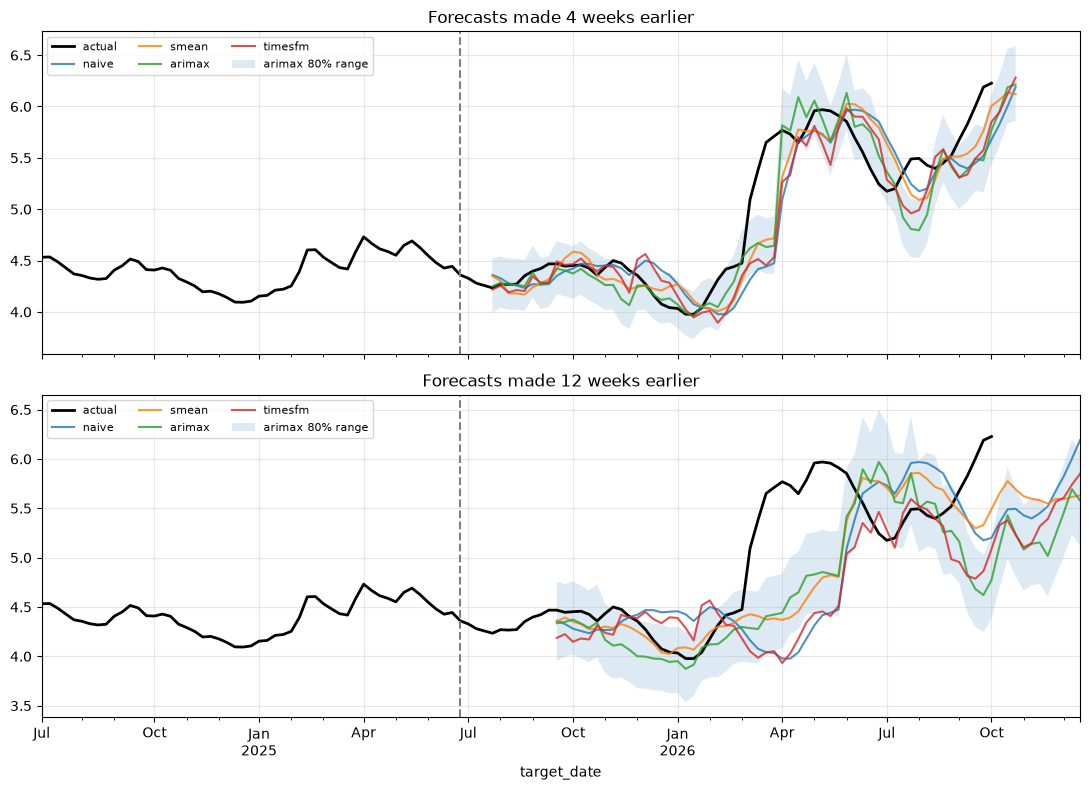

In [16]:
fig, axes = plt.subplots(len(SCORE_H), 1, figsize=(11, 8), sharex=True)
show = list(dict.fromkeys(["naive", "smean", best_conv] + COMBO[1:]))
for ax, h in zip(axes, SCORE_H):
    df.loc["2024-07":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
    for m in show:
        f = forecasts[m].query("horizon == @h").set_index("target_date")
        f["forecast"].plot(ax=ax, label=m, alpha=0.8)
    f = forecasts[best_conv].query("horizon == @h").set_index("target_date")
    ax.fill_between(f.index, f["lower80"], f["upper80"], alpha=0.15, label=f"{best_conv} 80% range")
    ax.axvline(pd.Timestamp(TRAIN_END), color="grey", ls="--")
    ax.set_title(f"Forecasts made {h} weeks earlier"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

### 4.5 How much error comes from not knowing future crude prices?
**What:** we rerun ARIMAX, but this time give it the **actual** future crude prices instead of assuming crude stays flat. No real forecaster has this information, so this is a check, not a forecast, and it never enters the rankings.

**How to read it:** the drop in error is the part caused by not knowing where crude goes. The rest comes from everything else: the seasonal pattern, refinery news, local shocks.

In [17]:
oracle_fc = backtest("arimax_oracle", make_arimax_ff(ARIMAX_FORM, ARIMAX_LAGS[ARIMAX_FORM], df["log_brent"]), verbose=False)
(FC_DIR / "arimax_oracle.csv").replace(RES_DIR / "arimax_oracle_forecasts.csv")   # keep out of the rankings

_, om = evaluate({"arimax": forecasts["arimax"], "arimax_oracle": oracle_fc, "naive": forecasts["naive"]})
oracle_tab = om["MAE"].unstack("model")[["arimax", "arimax_oracle"]]
oracle_tab["best_conventional"] = metrics["MAE"].xs(best_conv, level="model")
oracle_tab["share_of_ARIMAX_error_from_crude"] = 1 - oracle_tab["arimax_oracle"] / oracle_tab["arimax"]
oracle_tab = oracle_tab.round(3)
oracle_tab.to_csv(RES_DIR / "oracle_crude.csv")
for h, r in oracle_tab.iterrows():
    print(f"{h} weeks ahead: ARIMAX error {r.arimax:.3f} -> {r.arimax_oracle:.3f} with the real crude path "
          f"({r.share_of_ARIMAX_error_from_crude:.0%} of its error comes from not knowing crude)")
oracle_tab

4 weeks ahead: ARIMAX error 0.224 -> 0.178 with the real crude path (20% of its error comes from not knowing crude)
12 weeks ahead: ARIMAX error 0.502 -> 0.282 with the real crude path (44% of its error comes from not knowing crude)


model,arimax,arimax_oracle,best_conventional,share_of_ARIMAX_error_from_crude
horizon,,,,
4,0.224,0.178,0.224,0.205
12,0.502,0.282,0.502,0.438


## 5. Does crude oil lead gasoline prices?

**What:** a VAR model lets weekly crude changes and weekly gasoline changes predict each other (training data only).
- **Granger test:** does knowing past crude changes improve gasoline forecasts? *p below 0.05 means yes.* We also test the reverse.
- **Impulse response:** if crude suddenly rises 10%, how much does California gasoline rise over the following weeks?

Weeks of history used (chosen by AIC): 10
Does brent help predict ca_gas?  p = 0.0000  -> yes


Does ca_gas help predict brent?  p = 0.2130  -> no


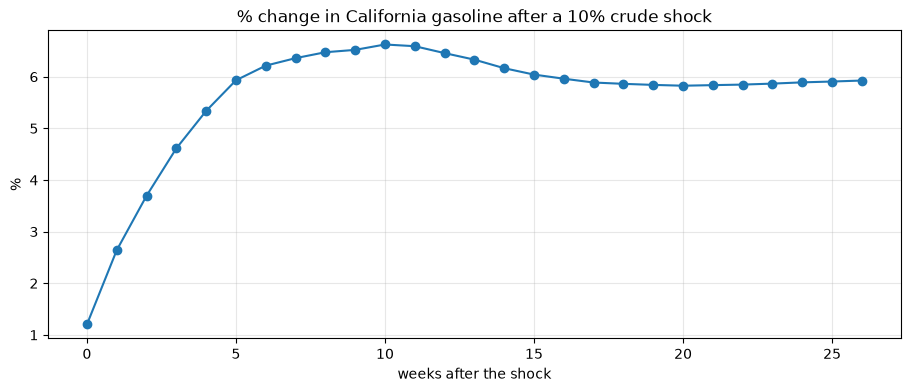

After 4 weeks: 5.3%, after 12 weeks: 6.5%


In [18]:
var_data = train[["log_brent", "log_ca_gas"]].diff().dropna()
var_data.columns = ["d_brent", "d_ca_gas"]
var_res = VAR(var_data).fit(maxlags=12, ic="aic")
print("Weeks of history used (chosen by AIC):", var_res.k_ar)

granger = {}
for caused, causing in [("d_ca_gas", "d_brent"), ("d_brent", "d_ca_gas")]:
    t = var_res.test_causality(caused, [causing], kind="f")
    granger[f"{causing}->{caused}"] = t.pvalue
    print(f"Does {causing.replace('d_', '')} help predict {caused.replace('d_', '')}?  p = {t.pvalue:.4f}"
          + ("  -> yes" if t.pvalue < 0.05 else "  -> no"))

oi = var_res.irf(26).orth_irfs   # [week, response, shock]
pass_through = pd.Series(np.cumsum(oi[:, 1, 0]) / oi[0, 0, 0] * 0.10, name="cumulative response")
ax = (pass_through * 100).plot(marker="o", title="% change in California gasoline after a 10% crude shock")
ax.set_xlabel("weeks after the shock"); ax.set_ylabel("%"); plt.show()
print(f"After 4 weeks: {pass_through[4]:.1%}, after 12 weeks: {pass_through[12]:.1%}")

## 6. Rockets and feathers: do pump prices rise faster than they fall?

**What:** an error-correction model. It separates crude **increases** from crude **decreases** and measures how much of each reaches the pump in the same week, after one week, and in total. It also lets prices drift back toward their long-run relationship with crude.

$$\Delta P_t = \alpha + \sum_{i=0}^{4} \beta_i^{+} \Delta C_{t-i}^{+} + \sum_{i=0}^{4} \beta_i^{-} \Delta C_{t-i}^{-} + \gamma (P_{t-1} - \theta C_{t-1} - \delta t) + \varepsilon_t$$

P = California gasoline price, C = Brent per gallon (USD/bbl ÷ 42).

**Why the time trend ($\delta t$):** the long-run link between gasoline and crude only holds once we allow for a steady upward drift (taxes and California-specific costs). The first test below shows this.

**How to read it:** in the table, compare the *increase* and *decrease* columns; **p below 0.05** (or 0.10, weaker evidence) means they differ.

In [19]:
K_ECM = 4
P, C = train["ca_gas"], train["brent"] / 42
trend = pd.Series(np.arange(len(C)), index=C.index, name="trend")
coint_p = {label: coint(P, C, trend=tr)[1] for tr, label in [("c", "without trend"), ("ct", "with trend")]}
for label, p in coint_p.items():
    print(f"Long-run link between gas and crude, {label}: p = {p:.3f}" + ("  -> exists" if p < 0.05 else "  -> not found"))

lr = sm.OLS(P, sm.add_constant(pd.concat([C, trend], axis=1))).fit()
dC = C.diff()
ecm = pd.DataFrame({"dP": P.diff(), "ect_l1": lr.resid.shift(1)})
for i in range(K_ECM + 1):
    ecm[f"up_l{i}"] = dC.clip(lower=0).shift(i)
    ecm[f"down_l{i}"] = dC.clip(upper=0).shift(i)
ecm = ecm.dropna()
ecm_res = sm.OLS(ecm["dP"], sm.add_constant(ecm.drop(columns="dP"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
gamma = ecm_res.params["ect_l1"]
print(f"Gaps from the long-run link close by half in about {np.log(0.5) / np.log(1 + gamma):.0f} weeks")

up = [f"up_l{i}" for i in range(K_ECM + 1)]; down = [f"down_l{i}" for i in range(K_ECM + 1)]
names = list(ecm_res.params.index)

def wald_p(rows):
    # H0: increases and decreases pass through equally, for every row of (increase terms, decrease terms)
    R = np.zeros((len(rows), len(names)))
    for r, (u, d) in enumerate(rows):
        for v in u: R[r, names.index(v)] += 1
        for v in d: R[r, names.index(v)] -= 1
    return float(ecm_res.wald_test(R, scalar=True).pvalue)

tests = [{"test": label, "increase": ecm_res.params[up[:j + 1]].sum(), "decrease": ecm_res.params[down[:j + 1]].sum(),
          "p-value": wald_p([(up[:j + 1], down[:j + 1])])}
         for j, label in [(0, "same week"), (1, "within 1 week"), (K_ECM, "total, within 4 weeks")]]
tests.append({"test": "every week equal (joint test)", "increase": np.nan, "decrease": np.nan,
              "p-value": wald_p([([u], [d]) for u, d in zip(up, down)])})
asym = pd.DataFrame(tests).set_index("test").round(3)
first, total = asym.iloc[0], asym.iloc[2]
print(f"\nSame week: {first['increase']:.2f} of a crude increase reaches the pump vs {first['decrease']:.2f} of a decrease "
      f"(p = {first['p-value']:.3f})")
print(f"Total:     {total['increase']:.2f} vs {total['decrease']:.2f} (p = {total['p-value']:.3f})")
asym

Long-run link between gas and crude, without trend: p = 0.891  -> not found
Long-run link between gas and crude, with trend: p = 0.001  -> exists
Gaps from the long-run link close by half in about 30 weeks

Same week: 0.49 of a crude increase reaches the pump vs 0.24 of a decrease (p = 0.064)
Total:     1.10 vs 1.01 (p = 0.593)


,increase,decrease,p-value
test,,,
same week,0.489,0.245,0.064
within 1 week,0.794,0.509,0.096
"total, within 4 weeks",1.097,1.007,0.593
every week equal (joint test),NaN,NaN,0.394


## 7. AI vs conventional models (research question 3)

### 7.1 Time-series AI models
**What:** test-period accuracy of the AI models next to the conventional models and benchmarks. Red bars are AI.

**Could the AI models have seen the answers?** A model's release date is the latest its training data could reach. Chronos-Bolt (Nov 2024) came out before the test period, so it is the cleanest comparison. TimesFM 2.5 and Chronos-2 came out during it.

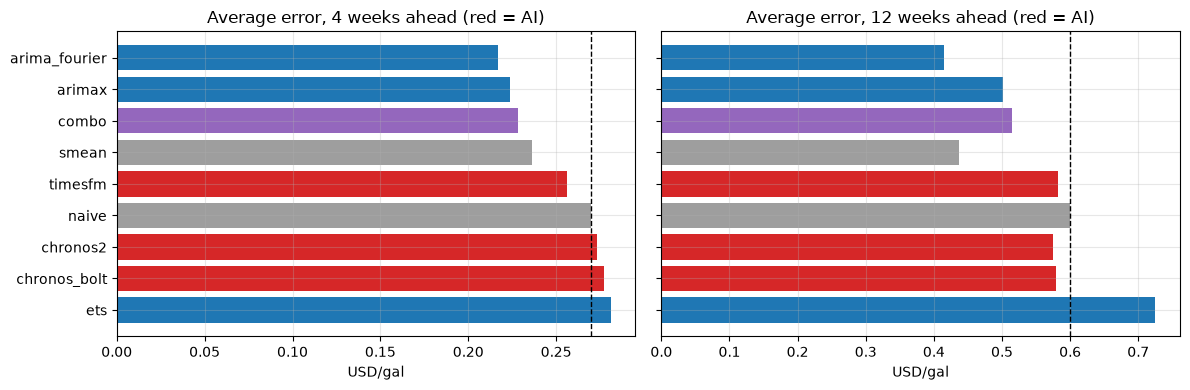

,horizon,model,type,MAE,Skill_vs_naive,DirAcc
0,4,arima_fourier,Conventional,0.217,0.803,71.429
1,4,arimax,Conventional,0.224,0.827,74.603
4,4,combo,Combination,0.228,0.845,71.429
7,4,smean,Benchmark,0.236,0.871,63.492
8,4,timesfm,AI,0.256,0.948,63.492
6,4,naive,Benchmark,0.270,1.000,NaN
2,4,chronos2,AI,0.273,1.009,58.730
3,4,chronos_bolt,AI,0.277,1.025,55.556
5,4,ets,Conventional,0.281,1.039,63.492
9,12,arima_fourier,Conventional,0.415,0.691,76.364


In [20]:
KIND = lambda m: ("AI" if is_ai(m) else "Benchmark" if m in ("naive", "smean") else
                  "Combination" if m == "combo" else "Conventional")
rows = []
for h in SCORE_H:
    mh = metrics.xs(h, level="horizon")
    for m in mh.index:
        if m not in ("snaive", "ardl") and not m.startswith("llm_"):
            rows.append({"horizon": h, "model": m, "type": KIND(m), "MAE": mh.loc[m, "MAE"],
                         "Skill_vs_naive": mh.loc[m, "Skill_vs_naive"], "DirAcc": mh.loc[m, "DirAcc"]})
ai_vs = pd.DataFrame(rows).sort_values(["horizon", "MAE"])

fig, axes = plt.subplots(1, len(SCORE_H), figsize=(12, 4), sharey=True)
colors = {"AI": "#d62728", "Conventional": "#1f77b4", "Benchmark": "#9e9e9e", "Combination": "#9467bd"}
for ax, h in zip(axes, SCORE_H):
    d = ai_vs[ai_vs.horizon == h].sort_values("MAE", ascending=False)
    ax.barh(d["model"], d["MAE"], color=d["type"].map(colors))
    ax.axvline(d.loc[d.model == "naive", "MAE"].iloc[0], color="k", ls="--", lw=1)
    ax.set_title(f"Average error, {h} weeks ahead (red = AI)"); ax.set_xlabel("USD/gal")
plt.tight_layout(); plt.show()
ai_vs.round(3)

### 7.2 LLM experiments (Claude, ChatGPT)
- **Anonymized:** the LLM sees only 156 weekly numbers rescaled to start at 100 — no name, no dates.
- **Full context:** the LLM is told it is California gasoline and gets dates, recent crude prices and news known on the forecast date.
- The gap between the two shows how much of the LLM's accuracy comes from background knowledge rather than reading the numbers.

LLMs run on only 17 dates (every 4th week), so here **every model is scored on those 17 dates only**. Prompts and replies are logged in `results/llm_log.jsonl`.

In [21]:
llm_models = [m for m in forecasts if m.startswith("llm_")]
if not llm_models:
    print("No LLM forecasts yet. Set ANTHROPIC_API_KEY and/or OPENAI_API_KEY, then run:\n"
          "  .venv-ai/bin/python llm/llm_experiments.py")
else:
    llm_dates = set(forecasts[llm_models[0]]["origin_date"])
    same = all_fc[all_fc["origin_date"].isin(llm_dates) & all_fc["horizon"].isin(SCORE_H)]
    keep = llm_models + ["naive", best_conv] + [m for m in forecasts if is_ai(m) and not m.startswith("llm_")]
    llm_table = (same[same.model.isin(keep)].assign(ae=lambda d: d.err.abs())
                 .pivot_table(index="model", columns="horizon", values="ae", aggfunc="mean").round(3).sort_values(SCORE_H[0]))
    llm_table.columns = [f"MAE h={h}" for h in llm_table.columns]
    print(f"Average error on the {len(llm_dates)} LLM forecast dates only")
    display(llm_table)

No LLM forecasts yet. Set ANTHROPIC_API_KEY and/or OPENAI_API_KEY, then run:
  .venv-ai/bin/python llm/llm_experiments.py


## 8. Scenario forecasts: what if there is a war, a ceasefire or a refinery outage?

**What:** we run one model twice — once assuming **no new event**, once assuming **an event happens** — and compare. The gap is the event's effect on gas prices.

**The model (ARDL):** next week's price change depends on the last 4 weeks of gas price changes, the last 0–8 weeks of crude changes, the seasonal pattern, and refinery-outage effects.

| Event | How it enters the model | Evidence |
|---|---|---|
| **War or ceasefire** | Change the future crude price path | Once crude is accounted for, gas prices rose no extra during past wars: wars work through crude |
| **Unplanned refinery outage** (fire, explosion) | Prices jump in weeks 1–3, then partly fall back in weeks 4–8 | Estimated from 4 past California outages (2012, 2012, 2015, 2025) |
| Planned refinery closure | Not included | No price jump at the Phillips 66 or Benicia closures; both were announced a year ahead |

**Why not ARIMAX here?** In this model a crude shock keeps feeding through as gas prices react to their own past changes, which matches how crude shocks actually spread. The 80% ranges come from 1,000 simulated price paths.

In [22]:
OUTAGES = {"Chevron Richmond fire": "2012-08-06", "ExxonMobil Torrance power outage": "2012-10-01",
           "ExxonMobil Torrance explosion": "2015-02-23", "Chevron El Segundo fire": "2025-10-06"}
SPIKE_W, RECOV_W = 3, 5     # weeks 1-3 prices jump, weeks 4-8 partly fall back
P_AR, Q_BRENT = 4, 8

def outage_dummies(index, starts):
    spike = pd.Series(0.0, index=index, name="outage_spike")
    rec = pd.Series(0.0, index=index, name="outage_recovery")
    for d in map(pd.Timestamp, starts):
        if d in index:
            i = index.get_loc(d)
            spike.iloc[i:i + SPIKE_W] = 1
            rec.iloc[i + SPIKE_W:i + SPIKE_W + RECOV_W] = 1
    return spike, rec

def seas_diff(dates):
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD) - fn(2 * np.pi * k * (t - 1) / PERIOD)
                         for k in range(1, K_BEST + 1) for f, fn in (("ds", np.sin), ("dc", np.cos))}, index=dates)

def fit_ardl(data):
    dy, db = data["log_ca_gas"].diff(), data["log_brent"].diff()
    spike, rec = outage_dummies(data.index, OUTAGES.values())
    X = pd.concat([pd.DataFrame({f"dy_l{i}": dy.shift(i) for i in range(1, P_AR + 1)}),
                   pd.DataFrame({f"db_l{k}": db.shift(k) for k in range(Q_BRENT + 1)}),
                   seas_diff(data.index), spike, rec], axis=1)
    d = pd.concat([dy.rename("dy"), sm.add_constant(X)], axis=1).dropna()
    return sm.OLS(d["dy"], d.drop(columns="dy")).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

def event_scenario(data=df, h=H, brent_path=None, outage_at=None, res=None, n_sims=1000, seed=0):
    # brent_path: future weekly Brent (USD/bbl); None = crude stays flat.
    # outage_at: week (1..h) when a new refinery outage starts; None = no outage.
    res = fit_ardl(data) if res is None else res
    b = res.params
    fut = future_dates(data, h)
    future_lb = np.log(brent_path) if brent_path is not None else data["log_brent"].iloc[-1]
    db = pd.concat([data["log_brent"], pd.Series(future_lb, index=fut)]).diff()
    spike, rec = outage_dummies(data.index.append(fut), list(OUTAGES.values()) + ([fut[outage_at - 1]] if outage_at else []))
    det = np.full(h, b["const"])
    for k in range(Q_BRENT + 1):
        det += b[f"db_l{k}"] * db.shift(k).loc[fut].values
    S = seas_diff(fut)
    for c in S:
        det += b[c] * S[c].values
    det += b["outage_spike"] * spike.loc[fut].values + b["outage_recovery"] * rec.loc[fut].values
    phi = b[[f"dy_l{i}" for i in range(1, P_AR + 1)]].values
    lags = np.tile(data["log_ca_gas"].diff().iloc[-P_AR:].values[::-1], (n_sims, 1))
    shocks = np.random.default_rng(seed).choice(res.resid.values, size=(n_sims, h))
    paths = np.zeros((n_sims, h))
    for s in range(h):
        paths[:, s] = det[s] + lags @ phi + shocks[:, s]
        lags = np.column_stack([paths[:, s], lags[:, :-1]])
    q = np.exp(np.percentile(data["log_ca_gas"].iloc[-1] + paths.cumsum(axis=1), [10, 50, 90], axis=0))
    return pd.DataFrame({"forecast": q[1], "lower80": q[0], "upper80": q[2]}, index=fut)

ardl_full = fit_ardl(df)
key = ["outage_spike", "outage_recovery"]
print(pd.DataFrame({"effect (% per week)": ardl_full.params[key] * 100, "p": ardl_full.pvalues[key]}).round(3))

                 effect (% per week)      p
outage_spike                   1.232  0.084
outage_recovery               -0.506  0.182


### 8.1 Sanity check: the effect of one event
**What:** how much higher the forecast is than the no-event baseline, for a permanent 10% crude rise and for a refinery outage.

**How to read it:** a 10% crude rise should lift gas prices by a few percent, close to the VAR result in section 5. An outage should cause a jump that partly fades.

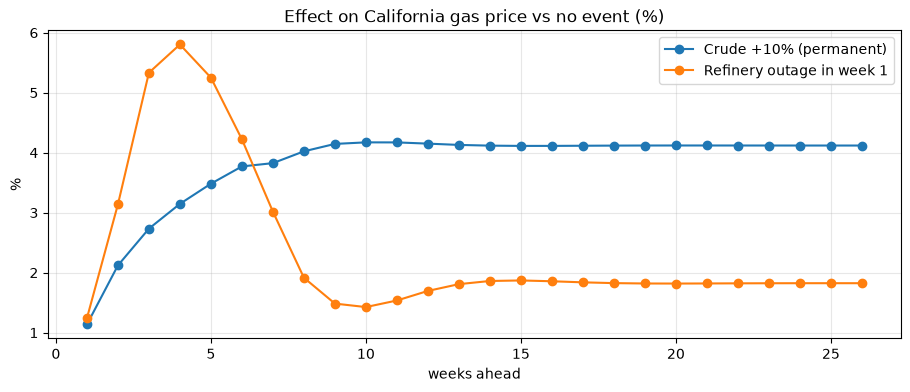

,Crude +10% (permanent),Refinery outage in week 1
1,1.14,1.24
2,2.12,3.14
4,3.15,5.80
8,4.02,1.92
12,4.15,1.70
26,4.12,1.82


In [23]:
last_brent = df["brent"].iloc[-1]
base = event_scenario(h=26)["forecast"]
check = pd.DataFrame({
    "Crude +10% (permanent)": event_scenario(h=26, brent_path=[last_brent * 1.1] * 26)["forecast"] / base - 1,
    "Refinery outage in week 1": event_scenario(h=26, outage_at=1)["forecast"] / base - 1,
})
check.index = range(1, 27)
ax = (check * 100).plot(marker="o", title="Effect on California gas price vs no event (%)")
ax.set_xlabel("weeks ahead"); ax.set_ylabel("%"); plt.show()
(check.loc[[1, 2, 4, 8, 12, 26]] * 100).round(2)

### 8.2 Event scenarios
**What:** 12-week forecasts under five scenarios. Sizes follow history: in the first month of the 2026 Iran war crude rose about 55%; after the April ceasefire it fell about 40% by July. Edit `SCENARIOS` to try others.

**How to read it:** the "vs baseline" columns show how much each event adds to (or takes off) the price, in dollars per gallon.

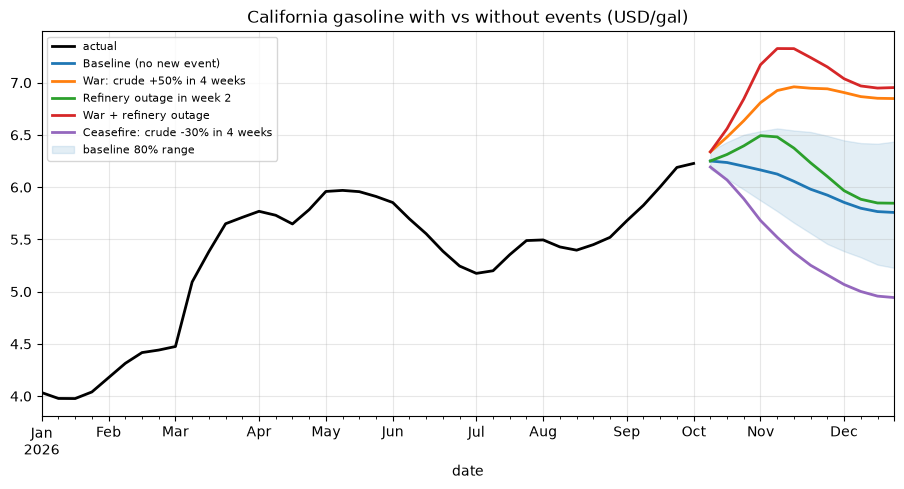

forecast             vs baseline            
weeks ahead                            4     8     12          4     8     12
scenario                                                                     
Baseline (no new event)              6.16  5.92  5.76        0.00  0.00  0.00
Ceasefire: crude -30% in 4 weeks     5.68  5.16  4.94       -0.48 -0.76 -0.81
Refinery outage in week 2            6.49  6.10  5.85        0.33  0.18  0.09
War + refinery outage                7.17  7.15  6.95        1.01  1.23  1.20
War: crude +50% in 4 weeks           6.81  6.94  6.85        0.64  1.02  1.09

In [24]:
def brent_ramp(mult, weeks, h=H):
    # crude moves to today's price x mult over `weeks` weeks, then stays there
    return last_brent * np.r_[np.linspace(1, mult, weeks + 1)[1:], np.repeat(mult, h - weeks)]

SCENARIOS = {
    "Baseline (no new event)": {},
    "War: crude +50% in 4 weeks": dict(brent_path=brent_ramp(1.5, 4)),
    "Refinery outage in week 2": dict(outage_at=2),
    "War + refinery outage": dict(brent_path=brent_ramp(1.5, 4), outage_at=2),
    "Ceasefire: crude -30% in 4 weeks": dict(brent_path=brent_ramp(0.7, 4)),
}
scen = {name: event_scenario(res=ardl_full, **kw) for name, kw in SCENARIOS.items()}

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for name, s in scen.items():
    s["forecast"].plot(ax=ax, lw=2, label=name)
b0 = scen["Baseline (no new event)"]
ax.fill_between(b0.index, b0["lower80"], b0["upper80"], color="C0", alpha=0.12, label="baseline 80% range")
ax.set_title("California gasoline with vs without events (USD/gal)"); ax.legend(fontsize=8); plt.show()

rows = [{"scenario": name, "weeks ahead": w, "forecast": s["forecast"].iloc[w - 1],
         "vs baseline": s["forecast"].iloc[w - 1] - b0["forecast"].iloc[w - 1]}
        for name, s in scen.items() for w in (4, 8, 12)]
scen_table = pd.DataFrame(rows).pivot(index="scenario", columns="weeks ahead", values=["forecast", "vs baseline"]).round(2)
scen_table.to_csv(RES_DIR / "event_scenarios.csv")
scen_table

### 8.3 Crude price scenarios (used by the dashboard)
**What:** `scenario()` takes a path of future weekly crude prices and returns a gas price forecast with an 80% range. The dashboard's *Crude Scenario* page uses it.

**How to read it:** "flat" means crude stays at today's price; in the other lines crude moves to the target over 4 weeks and stays there.

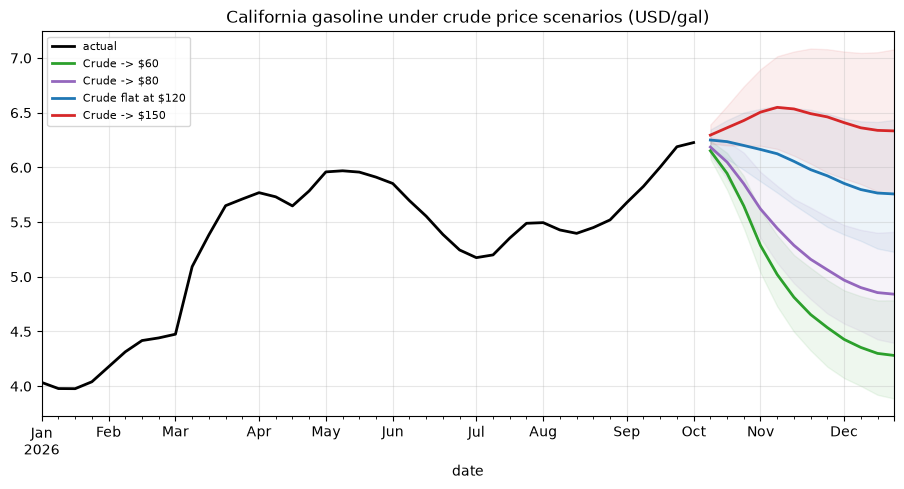

,4 weeks,8 weeks,12 weeks,12-week 80% range
Crude -> $60,5.286412,4.535536,4.280591,3.89 - 4.78
Crude -> $80,5.620017,5.063701,4.840781,4.40 - 5.41
Crude flat at $120,6.164047,5.923107,5.757179,5.23 - 6.43
Crude -> $150,6.505131,6.461612,6.333599,5.75 - 7.08


In [25]:
def scenario(brent_path, outage_at=None, data=df):
    res = ardl_full if data is df else None
    return event_scenario(data, h=len(brent_path), brent_path=np.asarray(brent_path, float), outage_at=outage_at, res=res)

BRENT_TARGETS = [60, 80, round(last_brent), 150]
price_scen = {(f"Crude flat at ${t}" if t == round(last_brent) else f"Crude -> ${t}"):
              scenario(brent_ramp(t / last_brent, 4)) for t in BRENT_TARGETS}

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for (name, s), color in zip(price_scen.items(), ["C2", "C4", "C0", "C3"]):
    s["forecast"].plot(ax=ax, lw=2, color=color, label=name)
    ax.fill_between(s.index, s["lower80"], s["upper80"], color=color, alpha=0.08)
ax.set_title("California gasoline under crude price scenarios (USD/gal)"); ax.legend(fontsize=8); plt.show()

brent_table = pd.DataFrame({name: {f"{w} weeks": s["forecast"].iloc[w - 1] for w in (4, 8, 12)}
                            | {"12-week 80% range": f"{s['lower80'].iloc[-1]:.2f} - {s['upper80'].iloc[-1]:.2f}"}
                            for name, s in price_scen.items()}).T
brent_table.to_csv(RES_DIR / "brent_scenarios.csv")
brent_table

### 8.4 Is the scenario model accurate?
**What:** the scenario model's no-event forecast, run through the same test as every other model.

**How to read it:** if it is close to the best models, its scenario numbers are believable. It is shown for reference and is not used when choosing the best model.

In [26]:
def ardl_ff(train, h):
    f = event_scenario(train, h, n_sims=500)
    f.index = range(1, h + 1)
    return f

forecasts["ardl"] = backtest("ardl", ardl_ff)
all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.xs("ardl", level="model")

  ardl: 1/66 forecast dates


  ardl: 21/66 forecast dates


  ardl: 41/66 forecast dates


  ardl: 61/66 forecast dates
  ardl: 66/66 forecast dates


,n,MAE,RMSE,MAPE,Coverage80,DirAcc,Skill_vs_naive
horizon,,,,,,,
4,63,0.235,0.326,4.540,0.683,71.429,0.868
12,55,0.476,0.638,8.694,0.636,74.545,0.793


## 9. Summary

**What:** collects the key numbers from every section, saves them to `results/summary.json` (the dashboard's home page reads this file), and prints the key findings. The findings at the top of this notebook are copied from here.

In [27]:
m4, m12 = metrics.xs(4, level="horizon"), metrics.xs(12, level="horizon")
contenders = [m for m in m4.index if KIND(m) != "Benchmark" and m not in ("snaive", "ardl") and not m.startswith("llm_")]
best_test = m4.loc[contenders, "MAE"].idxmin()
ai_test = [m for m in contenders if is_ai(m)]
best_ai_test = m4.loc[ai_test, "MAE"].idxmin() if ai_test else None
dmp = lambda m, h: float(dm_table.query("model == @m and vs == 'naive' and horizon == @h")["p"].iloc[0])

summary = {
    "data_end": str(df.index[-1].date()), "test_dates": int(len(ORIGINS)), "validation_dates": int(len(VAL_ORIGINS)),
    "arimax_crude_form": ARIMAX_FORM, "best_conventional_validation": best_conv, "combo": COMBO,
    "best_model_test": best_test,
    "mae": {m: {"h4": float(m4.loc[m, "MAE"]), "h12": float(m12.loc[m, "MAE"])} for m in contenders + ["naive", "smean"]},
    "best_vs_naive_dm_p": {"h4": dmp(best_test, 4), "h12": dmp(best_test, 12)},
    "best_ai_test": best_ai_test,
    "granger_crude_to_gas_p": float(granger["d_brent->d_ca_gas"]),
    "granger_gas_to_crude_p": float(granger["d_ca_gas->d_brent"]),
    "crude10_effect_4w": float(pass_through[4]), "crude10_effect_12w": float(pass_through[12]),
    "coint_p_no_trend": float(coint_p["without trend"]), "coint_p_trend": float(coint_p["with trend"]),
    "asym_first_week": {"up": float(first["increase"]), "down": float(first["decrease"]), "p": float(first["p-value"])},
    "asym_total": {"up": float(total["increase"]), "down": float(total["decrease"]), "p": float(total["p-value"])},
    "oracle_share": {"h4": float(oracle_tab.loc[4, "share_of_ARIMAX_error_from_crude"]),
                     "h12": float(oracle_tab.loc[12, "share_of_ARIMAX_error_from_crude"])},
    "summer_premium": float(premium),
    "naive_coverage": {"h4": float(m4.loc["naive", "Coverage80"]), "h12": float(m12.loc["naive", "Coverage80"])},
}
(RES_DIR / "summary.json").write_text(json.dumps(summary, indent=2))

s = summary
NICE = {"arima_fourier": "ARIMA + Fourier", "arimax": "ARIMAX", "ets": "ETS", "combo": "the combination",
        "timesfm": "TimesFM 2.5", "chronos2": "Chronos-2", "chronos_bolt": "Chronos-Bolt", "naive": "naive"}
nice = lambda m: NICE.get(m, m)
fmt = lambda m: f"{s['mae'][m]['h4']:.3f} / {s['mae'][m]['h12']:.3f}"
pfmt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
best, picked = s["best_model_test"], s["best_conventional_validation"]
picked_line = ("" if picked == best else
               f" The model picked in advance on the validation period, **{nice(picked)}**, scored {fmt(picked)}: "
               f"the validation winner did not stay on top in the test period, which is exactly the kind of result "
               f"that choosing on the test period would have hidden.")
ai_line = (f"No. The best AI model, **{nice(s['best_ai_test'])}**, scores {fmt(s['best_ai_test'])} vs {fmt(best)} "
           f"for {nice(best)} (naive: {fmt('naive')}). Combining an AI model with the best conventional model "
           f"({' + '.join(nice(m) for m in s['combo'])}: {fmt('combo')}) does not help either."
           if s["best_ai_test"] and s["mae"][s["best_ai_test"]]["h4"] > s["mae"][best]["h4"] else
           f"Best AI model: {nice(s['best_ai_test'])} ({fmt(s['best_ai_test'])})." if s["best_ai_test"] else "AI forecasts not loaded.")
findings = f'''
## Key findings
*From the latest run (data through {s["data_end"]}; test period = {s["test_dates"]} weekly forecasts from July 2025). Average error (MAE) in USD/gal, 4 / 12 weeks ahead.*

**1. How accurately can we forecast?** The most accurate model on the test period, **{nice(best)}**, misses by {fmt(best)} on average,
vs {fmt("naive")} for "same as this week" and {fmt("smean")} for the 10-year seasonal mean. It beats naive, but over a short test
period that includes a war the gain is not statistically significant ({pfmt(s["best_vs_naive_dm_p"]["h4"])} / {pfmt(s["best_vs_naive_dm_p"]["h12"])}).{picked_line}
Knowing future crude prices would cut ARIMAX's error by {s["oracle_share"]["h4"]:.0%} / {s["oracle_share"]["h12"]:.0%}: much of the remaining error is crude uncertainty.

**2. Does crude lead gasoline, and do prices rise faster than they fall?** Yes, crude leads ({pfmt(s["granger_crude_to_gas_p"])});
gasoline does not lead crude ({pfmt(s["granger_gas_to_crude_p"])}). A 10% crude rise lifts California prices about {s["crude10_effect_4w"]:.1%} within 4 weeks.
Increases reach the pump faster in the first week ({s["asym_first_week"]["up"]:.2f} vs {s["asym_first_week"]["down"]:.2f}, {pfmt(s["asym_first_week"]["p"])}, weak evidence),
but decreases catch up: the total effect is the same ({pfmt(s["asym_total"]["p"])}).

**3. Do AI forecasters beat conventional models?** {ai_line}
'''
display(Markdown(findings))


## Key findings
*From the latest run (data through 2026-10-05; test period = 66 weekly forecasts from July 2025). Average error (MAE) in USD/gal, 4 / 12 weeks ahead.*

**1. How accurately can we forecast?** The most accurate model on the test period, **ARIMA + Fourier**, misses by 0.217 / 0.415 on average,
vs 0.270 / 0.600 for "same as this week" and 0.236 / 0.437 for the 10-year seasonal mean. It beats naive, but over a short test
period that includes a war the gain is not statistically significant (p = 0.15 / p = 0.24). The model picked in advance on the validation period, **ARIMAX**, scored 0.224 / 0.502: the validation winner did not stay on top in the test period, which is exactly the kind of result that choosing on the test period would have hidden.
Knowing future crude prices would cut ARIMAX's error by 20% / 44%: much of the remaining error is crude uncertainty.

**2. Does crude lead gasoline, and do prices rise faster than they fall?** Yes, crude leads (p < 0.001);
gasoline does not lead crude (p = 0.21). A 10% crude rise lifts California prices about 5.3% within 4 weeks.
Increases reach the pump faster in the first week (0.49 vs 0.24, p = 0.06, weak evidence),
but decreases catch up: the total effect is the same (p = 0.59).

**3. Do AI forecasters beat conventional models?** No. The best AI model, **TimesFM 2.5**, scores 0.256 / 0.582 vs 0.217 / 0.415 for ARIMA + Fourier (naive: 0.270 / 0.600). Combining an AI model with the best conventional model (ARIMAX + TimesFM 2.5: 0.228 / 0.515) does not help either.


## Output files
| File | Contents |
|---|---|
| `forecasts/<model>.csv` | Test-period forecasts for every model (the dashboard reads these) |
| `forecasts_validation/<model>.csv` | Validation-period forecasts, used only to choose models |
| `results/validation_metrics.csv` | Validation scores behind every model choice |
| `results/metrics.csv`, `results/dm_tests.csv` | Test-period accuracy and significance tests |
| `results/oracle_crude.csv` | How much error comes from not knowing future crude |
| `results/event_scenarios.csv`, `results/brent_scenarios.csv` | Scenario forecasts |
| `results/summary.json` | Key numbers (read by the dashboard home page) |